# Truncatiebewuste MX-training: honderd epochs
CNN-8 / SVHN train-only. E2M3-bron en E2M1 uit diezelfde codes via `>> 2`, met
identieke schalen; A32 en FP32-updatemasters. Dit notebook leest uitsluitend
opgeslagen onderzoeksgegevens; geen training, datadownload of modelwijzigingen.
De laatste epoch en het geselecteerde beste checkpoint worden apart getoond.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_truncation_aware_reference100\\20261021_153559_999222_joint_run')
BASELINE_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_weights_dual_reference100\\20261019_192538_709626_joint_run')  # Optioneel: oude directe tweemodusrun


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def read_json(name):
    return json.loads((RUN_DIR / name).read_text(encoding="utf-8"))
report = read_json("run_report.json")
assert report["schema"] == "mx-truncation-aware-reference100-report-v1", "Verkeerde runmap"
assert report["config"]["truncation"] is True
synthetic = report.get("synthetic_fixture_only", False)
if synthetic:
    display(Markdown("**KUNSTMATIGE CPU-TESTDATA: GEEN ONDERZOEKSRESULTATEN.**"))
if report["status"] != "PASS":
    display(Markdown("**Deze run is niet volledig geslaagd: " + report["status"] + ".**"))
metrics = pd.read_csv(RUN_DIR / "epoch_metrics.csv")
selected = pd.read_csv(RUN_DIR / "selected_metrics.csv")
history = read_json("history.json")
summary = read_json("training_summary.json")
assert summary["optimizer_steps"] == summary["completed_epochs"] * ((report['config']['train_examples'] + report['config']['batch_size'] - 1) // report['config']['batch_size'])
assert not metrics.duplicated(["epoch", "phase", "weight_bits"]).any()
assert len(metrics) == summary["completed_epochs"] * 4
assert metrics[["objective_loss","count_top1_percent"]].notna().all().all()
assert ((100*metrics.correct1/metrics.n - metrics.count_top1_percent).abs() < 1e-8).all()
display(pd.DataFrame([{k:summary.get(k) for k in ["planned_epochs","completed_epochs","full_training_completed","optimizer_steps","training_forward_passes","truncation","measured_completed_epoch_seconds"]}]))
display(selected[["role","epoch","weight_bits","weight_format","bn_bank_key","count_top1_percent","objective_loss"]])
completion=read_json("completion_summary.json")
assert completion == summary
assert summary["full_training_completed"] == (summary["completed_epochs"] == 100)
if not summary["full_training_completed"]:
    display(Markdown("**ONVOLLEDIGE RUN: niet als honderd-epochresultaat rapporteren.**"))
else:
    assert len(metrics) == 400
    display(Markdown("**Honderd epochs voltooid.**"))


,planned_epochs,completed_epochs,full_training_completed,optimizer_steps,training_forward_passes,truncation,measured_completed_epoch_seconds
0,100,100,True,57300,114600,True,3939.265023


,role,epoch,weight_bits,weight_format,bn_bank_key,count_top1_percent,objective_loss
0,best_E2M3_test,52,4,MXFP4_E2M1,4,95.009988,0.188351
1,best_E2M3_test,52,6,MXFP6_E2M3,32,95.075292,0.214485
2,last_epoch,100,4,MXFP4_E2M1,4,94.940842,0.194402
3,last_epoch,100,6,MXFP6_E2M3,32,94.963891,0.238914


**Honderd epochs voltooid.**

## Leercurves
De testloss is voor beide modi hard-label cross-entropy. De hoge trainingsloss is hard-label CE; de lage trainingsloss is soft-target CE met de losgekoppelde E2M3-teacher. Deze verschillende trainingsdoelen mogen niet als dezelfde grootheid worden behandeld.

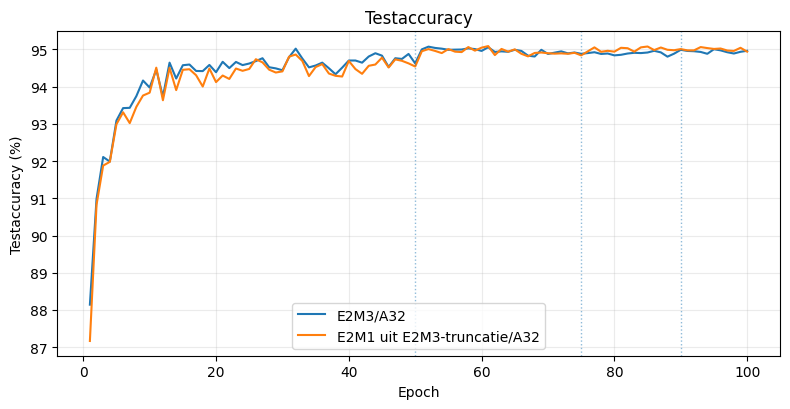

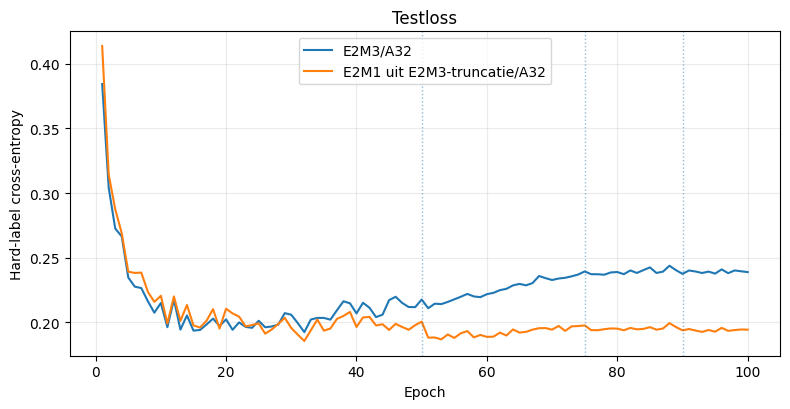

In [3]:
labels = {6:"E2M3/A32",4:"E2M1 uit E2M3-truncatie/A32"}
fig, ax = plt.subplots(figsize=(8,4.2))
for bit in [6,4]:
    d=metrics[(metrics.phase=="test") & (metrics.weight_bits==bit)]
    ax.plot(d.epoch,d.count_top1_percent, label=labels[bit])
ax.set(xlabel="Epoch",ylabel="Testaccuracy (%)",title="Kunstmatige testdata" if synthetic else "Testaccuracy")
for milestone in (50,75,90):
    if milestone <= summary["completed_epochs"]:
        ax.axvline(milestone, linestyle=":", linewidth=1, alpha=.5)
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,4.2))
for bit in [6,4]:
    d=metrics[(metrics.phase=="test") & (metrics.weight_bits==bit)]
    ax.plot(d.epoch,d.objective_loss,label=labels[bit])
ax.set(xlabel="Epoch",ylabel="Hard-label cross-entropy",title="Testloss")
for milestone in (50,75,90):
    if milestone <= summary["completed_epochs"]:
        ax.axvline(milestone, linestyle=":", linewidth=1, alpha=.5)
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## Gedeelde bron, gradients en BatchNorm
Elke trainingsminibatch heeft twee forwards en een gezamenlijke Adam-update. De zes hoge laagbronnen worden eenmaal gevormd en voor beide modi gebruikt. Schalen, teken en exponent blijven bij de lage afleiding behouden. De cache wordt voor de optimizerupdate opgeruimd; na een update mag een nieuwe hoge bron ontstaan.

In [4]:
audit_rows=[]
for e in history["epochs"]:
    g=e["gradient_checks"]; src=g["shared_source_checks"]
    assert src["source_cache_cleared"] and src["no_direct_low_quantizer"]
    assert src["high_encodings"] == src["low_from_same_source"] == 6*src["source_pairs"]
    assert g["detached_teacher_checks"] == g["finite_gradient_checks"] == src["source_pairs"]
    assert e["batchnorm_counters_correct"] and e["test_optimizer_steps"]==0
    test_src=e["test_source_checks"]
    assert test_src["source_cache_cleared"]
    audit_rows.append({"epoch":e["epoch"],"updates":g["optimizer_steps_in_phase"],
        "high_encodings":src["high_encodings"],"low_from_same_high":src["low_from_same_source"],
        "gradient_norm_max":g["gradient_l2_max"],"BN_ok":e["batchnorm_counters_correct"]})
display(pd.DataFrame(audit_rows).tail(12))
updates=pd.read_csv(RUN_DIR/"weight_updates.csv")
display(updates.groupby(["epoch","weight_bits"])[["changed_element_codes_including_padding","changed_scale_codes"]].sum().tail(24))
display(Markdown("Master-updatewaarden staan voor beide modi herhaald in het bronbestand: **niet dubbel optellen**."))
display(pd.DataFrame(report.get("warnings",[])))

,epoch,updates,high_encodings,low_from_same_high,gradient_norm_max,BN_ok
88,89,573,3438,3438,2.034730,True
89,90,573,3438,3438,1.968218,True
90,91,573,3438,3438,1.973413,True
91,92,573,3438,3438,3.322223,True
92,93,573,3438,3438,1.926914,True
93,94,573,3438,3438,1.754032,True
94,95,573,3438,3438,1.819404,True
95,96,573,3438,3438,2.281400,True
96,97,573,3438,3438,2.952925,True
97,98,573,3438,3438,1.686146,True


changed_element_codes_including_padding  \
epoch weight_bits                                            
89    4                                                843   
      6                                               2363   
90    4                                                924   
      6                                               2406   
91    4                                                150   
      6                                                314   
92    4                                                155   
      6                                                326   
93    4                                                140   
      6                                                306   
94    4                                                155   
      6                                                310   
95    4                                                156   
      6                                                304   
96    4                                                204   
      6                                                345   
97    4                                                154   
      6                                                292   
98    4                                                188   
      6                                                346   
99    4                                                169   
      6                                                320   
100   4                                                182   
      6                                                330   

                   changed_scale_codes  
epoch weight_bits                       
89    4                              2  
      6                              2  
90    4                              3  
      6                              3  
91    4                              0  
      6                              0  
92    4                              1  
      6                              1  
93    4                              0  
      6                              0  
94    4                              0  
      6                              0  
95    4                              0  
      6                              0  
96    4                              1  
      6                              1  
97    4                              0  
      6                              0  
98    4                              1  
      6                              1  
99    4                              0  
      6                              0  
100   4                              0  
      6                              0

Master-updatewaarden staan voor beide modi herhaald in het bronbestand: **niet dubbel optellen**.

,category,message,file,line
0,DeprecationWarning,The argument 'device' of Tensor.pin_memory() i...,C:\Users\renzo\master-thesis-mx\.venv-train\Li...,57
1,DeprecationWarning,The argument 'device' of Tensor.is_pinned() is...,C:\Users\renzo\master-thesis-mx\.venv-train\Li...,57


## Gemeten tijd en exports
Bij een volledige run is de som van de honderd epochtijden de gemeten duur,
geen extrapolatie. Die som omvat training, test, controles en checkpointopslag;
sessie-opstart en eindexport staan apart. Bij hervatten tellen we alle epochs,
maar de sessiewandtijd geldt uitsluitend voor het huidige proces.
De hoge export bevat codes, schalen en aanvullende laag-/BN-staat, geen zes
FP32-masters. De lage export is alleen uit de herladen hoge bron afgeleid.
Een exacte gewichtstest is geen extra volledige testevaluatie van de exports.


In [5]:
times=pd.read_csv(RUN_DIR/"epoch_times.csv")
estimate=read_json("timing_estimate.json")
assert len(times) == summary["completed_epochs"]
measured=float(times.total_epoch_seconds.sum())
assert abs(measured-summary["measured_completed_epoch_seconds"]) < 1e-5
print(f"Gemeten totale epochtijd: {measured/60:.2f} minuten")
if report.get("session_wall_seconds") is not None:
    print(f"Gemeten duur van deze sessie: {report['session_wall_seconds']/60:.2f} minuten")
if report.get("resumed_from"):
    print("Hervatte run: de sessieduur bevat niet de eerdere sessies of de pauze.")
if not summary["full_training_completed"] and estimate.get("available"):
    print(f"Voorlopige projectie naar 100 epochs: {estimate['estimated_100_epoch_seconds']/60:.2f} minuten")
display(times[["epoch","train_seconds","test_seconds","total_epoch_seconds"]].tail(12))
export_rows=[]
for role,modes in report.get("mx_exports",{}).items():
    for bit,data in modes.items():
        export_rows.append({"rol":role,"bits":bit,"epoch":data["epoch"],
            "gewichten_exact":data["decoded_weights_exact"],
            "masters_afwezig":data["six_fp32_masters_absent"],
            "lage_export_uit_herladen_hoge_bron":data["derived_from_reloaded_high_only"],
            "volledige_test_opnieuw":data["full_test_forward_rerun"]})
display(pd.DataFrame(export_rows))


Gemeten totale epochtijd: 65.65 minuten
Gemeten duur van deze sessie: 65.79 minuten


,epoch,train_seconds,test_seconds,total_epoch_seconds
88,89,32.389680,9.118707,41.652147
89,90,32.953144,9.020774,42.117382
90,91,32.794981,9.222367,42.161403
91,92,33.085798,9.014638,42.252104
92,93,32.952154,9.129330,42.231907
93,94,33.036521,9.105819,42.284156
94,95,32.934675,9.098516,42.181068
95,96,32.857383,9.071285,42.078486
96,97,33.025629,8.988012,42.157740
97,98,32.874881,9.055382,42.076953


,rol,bits,epoch,gewichten_exact,masters_afwezig,lage_export_uit_herladen_hoge_bron,volledige_test_opnieuw
0,best_E2M3_test,6,52,True,True,False,False
1,best_E2M3_test,4,52,True,True,True,False
2,last_epoch,6,100,True,True,False,False
3,last_epoch,4,100,True,True,True,False


## Optionele vergelijking met de directe tweemodusreferentie
Vul `BASELINE_DIR` in om dezelfde epochs te vergelijken, met epoch 100 als vast
eindpunt zodra beide runs voltooid zijn. De lage baseline gebruikt directe
kwantisatie; dit nieuwe model gebruikt truncatie tijdens training en uitvoering.
Dit is niet dezelfde vergelijking als achteraf trunceren van het baselinemodel.
Een seed en testgestuurde checkpointselectie beperken de conclusies; herstel
van de eerder gemeten kloof is niet gegarandeerd. BN-aanpassing aan truncatie
is onderdeel van de nieuwe trainingsmethode, niet afzonderlijk geisoleerd.


In [6]:
if BASELINE_DIR is not None:
    base=Path(BASELINE_DIR)
    baseline_report=json.loads((base/"run_report.json").read_text(encoding="utf-8"))
    bc=baseline_report["config"]; tc=report["config"]
    assert bc["truncation"] is False
    for key in ["model","expand","train_examples","test_examples","activation_bits","batch_size","optimizer","lr","weight_decay","scheduler_milestones","seed","weight_bits","bn_bank_mapping"]:
        assert tc[key]==bc[key], f"Protocolverschil: {key}"
    if "initial_model_sha256" in baseline_report:
        assert baseline_report["initial_model_sha256"]==report["initial_model_sha256"]
    base_history=json.loads((base/"history.json").read_text(encoding="utf-8"))
    old_hist={e["epoch"]:e for e in base_history["epochs"]}
    same_order=True
    for e in history["epochs"]:
        if e["epoch"] in old_hist:
            for phase in ("train","test"):
                same_order &= e["coverage"][phase]["order_sha256"] == old_hist[e["epoch"]]["coverage"][phase]["order_sha256"]
    print("Geregistreerde samplevolgorde gelijk op overlappende epochs:", same_order)
    if not same_order:
        display(Markdown("**Let op: samplevolgorde verschilt; geen volledig gematchte uitvoering.**"))
    print("Softwareomgeving gelijk:", baseline_report.get("environment")==report.get("environment"))
    print("Backendinstellingen gelijk:", baseline_report.get("execution_settings")==report.get("execution_settings"))
    old=pd.read_csv(base/"epoch_metrics.csv")
    new=metrics[metrics.phase=="test"]
    old=old[old.phase=="test"]
    comparison=new.merge(old,on=["epoch","weight_bits"],suffixes=("_trunc","_direct"),validate="one_to_one")
    comparison["verschil_procentpunt"]=comparison.count_top1_percent_trunc-comparison.count_top1_percent_direct
    display(comparison[comparison.epoch==comparison.epoch.max()][["epoch","weight_bits","count_top1_percent_direct","count_top1_percent_trunc","verschil_procentpunt"]])
    if comparison.epoch.max() < 100:
        print("Nog geen gemeenschappelijke epoch100; bovenstaande rij is voorlopig.")
    display(Markdown("Rapporteer alleen deze gelijk-epochvergelijking; dit is nog geen bewijs van een robuuste verbetering."))
else:
    print("Geen baselinepad ingevuld; alleen deze run getoond.")

Geregistreerde samplevolgorde gelijk op overlappende epochs: True
Softwareomgeving gelijk: True
Backendinstellingen gelijk: True


,epoch,weight_bits,count_top1_percent_direct,count_top1_percent_trunc,verschil_procentpunt
198,100,4,95.025353,94.940842,-0.084511
199,100,6,95.033036,94.963891,-0.069146


Rapporteer alleen deze gelijk-epochvergelijking; dit is nog geen bewijs van een robuuste verbetering.

## Volledige learning-rateplanning
De daling volgt na epochs 50, 75 en 90. De eerste epoch met een verlaagde LR
is dus respectievelijk 51, 76 en 91. Voor een onderbroken run tonen we alleen
werkelijk uitgevoerde epochs.

,epoch,lr_gebruikt,lr_volgende
0,1,0.001000,0.001000
48,49,0.001000,0.001000
49,50,0.001000,0.000100
50,51,0.000100,0.000100
73,74,0.000100,0.000100
74,75,0.000100,0.000010
75,76,0.000010,0.000010
88,89,0.000010,0.000010
89,90,0.000010,0.000001
90,91,0.000001,0.000001


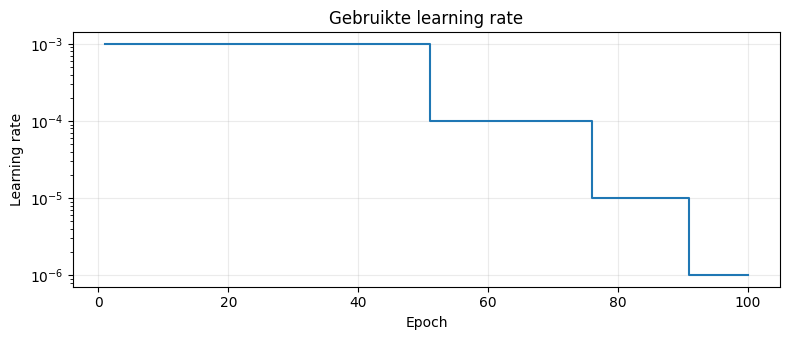

In [7]:
lr_rows=[]
for e in history["epochs"]:
    expected=.001
    next_lr=.001
    for boundary in (50,75,90):
        if boundary < e["epoch"]: expected *= .1
        if boundary <= e["epoch"]: next_lr *= .1
    assert e["lr_used"]==expected and e["lr_next"]==next_lr
    lr_rows.append({"epoch":e["epoch"],"lr_gebruikt":e["lr_used"],"lr_volgende":e["lr_next"]})
lrs=pd.DataFrame(lr_rows)
display(lrs[lrs.epoch.isin([1,49,50,51,74,75,76,89,90,91,100])])
fig,ax=plt.subplots(figsize=(8,3.5))
ax.step(lrs.epoch,lrs.lr_gebruikt,where="post")
ax.set(xlabel="Epoch",ylabel="Learning rate",yscale="log",title="Gebruikte learning rate")
ax.grid(alpha=.25);fig.tight_layout();plt.show()
